In [ ]:
!git clone https://github.com/qishenzhou/MMTD.git

In [ ]:
# MOVE FILES INTO data/mmtd
# mv "/mnt/d/C Drive Data/Downloads/distance_matrix.h5" ~/MMTD/data/mmtd/distance_matrix.h5


In [ ]:
!python -m pip install -r requirements.txt

In [ ]:
%cd ..

In [ ]:
!python -m examples.load_fixed_sensor --data-root ./data

In [ ]:
!git clone https://github.com/nnzhan/Graph-WaveNet.git

In [ ]:
%cd Graph-WaveNet

In [ ]:
!pip install torch numpy pandas h5py scipy scikit-learn

In [ ]:
pwd

'/content'

### Prepare MMTD data

In [1]:
from pathlib import Path

print("Current working dir:", Path.cwd())

MMTD_ROOT = None

# 1. Search current dir and ancestors first
for base in [Path.cwd(), *Path.cwd().parents]:
    if (base / "MMTD" / "data").is_dir():
        MMTD_ROOT = base / "MMTD"
        break
    if base.name == "MMTD" and (base / "data").is_dir():
        MMTD_ROOT = base
        break

# 2. Explicit fallback to known path if not found in parents
if MMTD_ROOT is None and Path("/home/aadiuntu/MMTD/data").is_dir():
    MMTD_ROOT = Path("/home/aadiuntu/MMTD")

if MMTD_ROOT is None:
    raise FileNotFoundError(f"Could not find MMTD/data from {Path.cwd()}")

Current working dir: /home/aadiuntu


In [2]:

import os
import h5py
import numpy as np
from pathlib import Path

# Locate the MMTD folder
MMTD_ROOT = None

for base in [Path.cwd(), *Path.cwd().parents]:
    if (base / "MMTD" / "data").is_dir():
        MMTD_ROOT = base / "MMTD"
        break
    if base.name == "MMTD" and (base / "data").is_dir():
        MMTD_ROOT = base
        break

if MMTD_ROOT is None:
    raise FileNotFoundError("Could not find MMTD/data")

DATA_DIR = MMTD_ROOT / "data"
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Fixed dataset dimensions
TIMESTAMPS = 2976
MAX_NODES = 2780
SEQ_LEN = 12
TARGET_FEATURE = 2

RAW_PATH = DATA_DIR / "fixed_sensor_data.h5"
WEATHER_PATH = DATA_DIR / "fixed_sensor_weather.h5"
WEATHER_256_PATH = DATA_DIR / "fixed_sensor_weather_256.h5"
ROAD_PATH = DATA_DIR / "road_info.h5"
FINAL_PATH = DATA_DIR / "fixed_sensor_weather_road_256.h5"

print("MMTD root:", MMTD_ROOT)
print("Data directory:", DATA_DIR)
print("Timestamps:", TIMESTAMPS)
print("Nodes:", MAX_NODES)
print("Sequence length:", SEQ_LEN)


MMTD root: /home/aadiuntu/MMTD
Data directory: /home/aadiuntu/MMTD/data
Timestamps: 2976
Nodes: 2780
Sequence length: 12


In [3]:

import shutil
import h5py
import numpy as np
import requests

# Reuse an existing weather-enriched file if available
use_existing_weather = False

if WEATHER_PATH.exists():
    with h5py.File(WEATHER_PATH, "r") as f:
        existing_shape = f["data/values"].shape
        existing_features = len(f["metadata/features"])

        if (
            existing_shape[0] >= TIMESTAMPS
            and existing_shape[1] >= MAX_NODES
            and existing_features == 6
        ):
            use_existing_weather = True

if use_existing_weather:
    print("Reusing existing weather-enriched data. No API request.")

    with h5py.File(WEATHER_PATH, "r") as f:
        combined = f["data/values"][
            :TIMESTAMPS, :MAX_NODES, :
        ].astype(np.float32)

        features = [
            x.decode() if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]

        node_ids = f["metadata/nodes"][:MAX_NODES]

    base_path = WEATHER_PATH

else:
    print("No reusable weather file found. Downloading weather.")

    with h5py.File(RAW_PATH, "r") as f:
        traffic = f["data/values"][
            :TIMESTAMPS, :MAX_NODES, :
        ].astype(np.float32)

        old_features = [
            x.decode() if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]

        node_ids = f["metadata/nodes"][:MAX_NODES]

    # Fetch enough historical weather for the first 256 traffic timestamps
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 40.4168,
            "longitude": -3.7038,
            "start_date": "2024-08-01",
            "end_date": "2024-08-03",
            "hourly": "temperature_2m,relative_humidity_2m,precipitation",
            "timezone": "Europe/Madrid",
        },
        timeout=60,
    )
    response.raise_for_status()

    hourly = response.json()["hourly"]

    weather_hourly = np.column_stack([
        hourly["temperature_2m"],
        hourly["relative_humidity_2m"],
        hourly["precipitation"],
    ]).astype(np.float32)

    # Convert hourly weather into 15-minute intervals
    weather_15min = np.repeat(weather_hourly, 4, axis=0)

    weather_15min = weather_15min[:TIMESTAMPS]

    assert len(weather_15min) == TIMESTAMPS

    # Repeat weather across the 256 sensors
    weather_all_sensors = np.broadcast_to(
        weather_15min[:, None, :],
        (TIMESTAMPS, MAX_NODES, 3)
    ).copy()

    combined = np.concatenate(
        [traffic, weather_all_sensors],
        axis=2
    )

    features = old_features + [
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
    ]

    base_path = RAW_PATH


# Save a physically cropped HDF5 file
shutil.copy2(base_path, WEATHER_256_PATH)

with h5py.File(WEATHER_256_PATH, "r+") as f:

    attrs = {}

    if "data/values" in f:
        attrs = dict(f["data/values"].attrs)
        del f["data/values"]

    new_values = f["data"].create_dataset(
        "values",
        data=combined,
        compression="gzip",
        compression_opts=4
    )

    for key, value in attrs.items():
        new_values.attrs[key] = value

    # Ensure metadata contains only the selected nodes
    if "metadata/nodes" in f:
        del f["metadata/nodes"]

    f["metadata"].create_dataset(
        "nodes",
        data=node_ids
    )

    if "metadata/features" in f:
        del f["metadata/features"]

    f["metadata"].create_dataset(
        "features",
        data=np.asarray(
            features,
            dtype=h5py.string_dtype("utf-8")
        )
    )

print("Weather dataset saved:", WEATHER_256_PATH)
print("Shape:", combined.shape)
print("Features:", len(features))



Reusing existing weather-enriched data. No API request.
Weather dataset saved: /home/aadiuntu/MMTD/data/fixed_sensor_weather_256.h5
Shape: (2976, 2780, 6)
Features: 6


In [4]:

import shutil
import h5py
import numpy as np

def node_key(value):
    if isinstance(value, np.generic):
        value = value.item()

    if isinstance(value, bytes):
        value = value.decode("utf-8")

    return str(value).strip()


# Read the cropped weather dataset
with h5py.File(WEATHER_256_PATH, "r") as f:
    traffic_weather = f["data/values"][:].astype(np.float32)
    traffic_nodes = f["metadata/nodes"][:]

    traffic_features = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]


# Read road information
with h5py.File(ROAD_PATH, "r") as f:
    road_values = f["data/values"][:].astype(np.float32)
    road_nodes = f["metadata/nodes"][:]

    road_features = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]


# Match the selected 256 traffic sensors to road rows
road_row_by_id = {
    node_key(node): i
    for i, node in enumerate(road_nodes)
}

missing = [
    node for node in traffic_nodes
    if node_key(node) not in road_row_by_id
]

print("Selected traffic nodes:", len(traffic_nodes))
print("Unmatched nodes:", len(missing))

if missing:
    raise ValueError(
        f"Some selected sensors have no road match: {missing[:5]}"
    )

row_indices = [
    road_row_by_id[node_key(node)]
    for node in traffic_nodes
]

road_aligned = road_values[row_indices]

# Repeat static road features across 256 timestamps
road_over_time = np.broadcast_to(
    road_aligned[None, :, :],
    (
        TIMESTAMPS,
        MAX_NODES,
        road_aligned.shape[1]
    )
).copy()

# Combine weather, traffic, and road features
combined = np.concatenate(
    [traffic_weather, road_over_time],
    axis=2
)

features = traffic_features + [
    f"road_{name}" for name in road_features
]

print("Final feature count:", len(features))

assert combined.shape[2] == 49, (
    f"Expected 49 features, got {combined.shape[2]}"
)

# Save final dataset
shutil.copy2(WEATHER_256_PATH, FINAL_PATH)

with h5py.File(FINAL_PATH, "r+") as f:

    attrs = dict(f["data/values"].attrs)
    del f["data/values"]

    new_values = f["data"].create_dataset(
        "values",
        data=combined,
        compression="gzip",
        compression_opts=4
    )

    for key, value in attrs.items():
        new_values.attrs[key] = value

    del f["metadata/features"]

    f["metadata"].create_dataset(
        "features",
        data=np.asarray(
            features,
            dtype=h5py.string_dtype("utf-8")
        )
    )

print("Final dataset saved:", FINAL_PATH)
print("Final shape:", combined.shape)


Selected traffic nodes: 2780
Unmatched nodes: 0
Final feature count: 49
Final dataset saved: /home/aadiuntu/MMTD/data/fixed_sensor_weather_road_256.h5
Final shape: (2976, 2780, 49)


### Preprocessing

In [5]:

import shutil
import h5py
import numpy as np
import requests

source_path = DATA_DIR / "fixed_sensor_data.h5"
weather_path = DATA_DIR / "fixed_sensor_weather.h5"

if weather_path.exists():
    print("Weather-enriched file already exists. Skipping API request.")

else:
    print("Downloading historical weather data...")

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 40.4168,
            "longitude": -3.7038,
            "start_date": "2024-08-01",
            "end_date": "2024-08-31",
            "hourly": "temperature_2m,relative_humidity_2m,precipitation",
            "timezone": "Europe/Madrid",
        },
        timeout=60,
    )
    response.raise_for_status()

    hourly = response.json()["hourly"]

    weather_hourly = np.column_stack([
        hourly["temperature_2m"],
        hourly["relative_humidity_2m"],
        hourly["precipitation"],
    ]).astype(np.float32)

    # One hourly weather reading is repeated for four 15-minute intervals
    weather_15min = np.repeat(weather_hourly, 4, axis=0)

    with h5py.File(source_path, "r") as f:
        traffic = f["data/values"][:].astype(np.float32)

        old_features = [
            x.decode() if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]

    T_weather, N_weather, _ = traffic.shape

    assert T_weather == len(weather_15min), (
        f"Traffic timestamps: {T_weather}; "
        f"weather timestamps: {len(weather_15min)}"
    )

    weather_all_sensors = np.broadcast_to(
        weather_15min[:, None, :],
        (T_weather, N_weather, 3)
    ).copy()

    combined = np.concatenate(
        [traffic, weather_all_sensors],
        axis=2
    )

    new_features = old_features + [
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
    ]

    shutil.copy2(source_path, weather_path)

    with h5py.File(weather_path, "r+") as f:
        attrs = dict(f["data/values"].attrs)
        del f["data/values"]

        new_values = f["data"].create_dataset(
            "values",
            data=combined,
            compression="gzip",
            compression_opts=4
        )

        for key, value in attrs.items():
            new_values.attrs[key] = value

        del f["metadata/features"]
        f["metadata"].create_dataset(
            "features",
            data=np.asarray(
                new_features,
                dtype=h5py.string_dtype("utf-8")
            )
        )

    print("Saved:", weather_path)

print("Weather preprocessing complete.")


Weather-enriched file already exists. Skipping API request.
Weather preprocessing complete.


In [ ]:
# mean = values[:train_end].mean(axis=0)
# std = values[:train_end].std(axis=0)
# std[std < 1e-6] = 1.0

# normalized = (values - mean[None, :, :]) / std[None, :, :]

# # Create sliding windows
# # # X: (samples, time, nodes, features)
# # # (T = 2976-12, 12, 256, 3)
# # X = np.stack([
# #     normalized[i:i + SEQ_LEN]
# #     for i in range(T - SEQ_LEN)
# # ])

# # # y: congestion, shape (samples, 1, nodes)
# # # because 1 output feature - (2976-12, 1, 256)
# # y = normalized[SEQ_LEN:, :, TARGET_FEATURE][:, None, :]

# # # Split according to target timestamps
# # train_count = train_end - SEQ_LEN
# # val_count = val_end - train_end

# # splits = {
# #     "train": (X[:train_count], y[:train_count]),
# #     "valid": (
# #         X[train_count:train_count + val_count],
# #         y[train_count:train_count + val_count]
# #     ),
# #     "test": (
# #         X[train_count + val_count:],
# #         y[train_count + val_count:]
# #     )
# # }

# # for name, (x, target) in splits.items():
# #     path = os.path.join(OUTPUT_DIR, f"{name}.npz")
# #     np.savez_compressed(path, x=x, y=target)
# #     print(name, x.shape, target.shape, "->", path)

# # Create memory-mapped sliding windows on D:


# # save preprocessed data
# np.savez(
#     os.path.join(OUTPUT_DIR, "scaler.npz"),
#     mean=mean,
#     std=std,
#     node_ids=node_ids
# )

In [6]:
import gc
import h5py
import numpy as np

# Free any existing large arrays first if re-running
for name in ["values", "normalized"]:
    if name in globals():
        del globals()[name]
gc.collect()

with h5py.File(FINAL_PATH, "r") as f:
    ds = f["data/values"]
    T, N, F = ds.shape
    values = np.empty((T, N, F), dtype=np.float32)

    STEP = 256
    for start in range(0, T, STEP):
        end = min(start + STEP, T)
        values[start:end] = ds[start:end].astype(np.float32)

    node_ids = f["metadata/nodes"][:]
    features = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]

print("Final dataset shape:", values.shape)
print("Timestamps:", T)
print("Nodes:", N)
print("Features:", F)

assert SEQ_LEN == 12
assert features[TARGET_FEATURE] == "conges_levl"

print("All dimensions correct!")

Final dataset shape: (2976, 2780, 49)
Timestamps: 2976
Nodes: 2780
Features: 49
All dimensions correct!


In [7]:
import gc
import numpy as np
import h5py

if "values" not in globals():
    with h5py.File(FINAL_PATH, "r") as f:
        values = f["data/values"][:].astype(np.float32)
elif values.dtype != np.float32:
    values = values.astype(np.float32)

T, N, F = values.shape
train_end = int(T * 0.70)
val_end = int(T * 0.80)
CHUNK_SIZE = 64

# --------------------------------------------------
# 1. Per-node, per-feature means on finite train data
# --------------------------------------------------
sums = np.zeros((N, F), dtype=np.float64)
counts = np.zeros((N, F), dtype=np.int64)
global_sums = np.zeros(F, dtype=np.float64)
global_counts = np.zeros(F, dtype=np.int64)

for start in range(0, train_end, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, train_end)
    chunk = values[start:end]
    finite_mask = np.isfinite(chunk)

    sums += np.sum(chunk, axis=0, where=finite_mask, dtype=np.float64)
    counts += finite_mask.sum(axis=0)
    global_sums += np.sum(chunk, axis=(0, 1), where=finite_mask, dtype=np.float64)
    global_counts += finite_mask.sum(axis=(0, 1))
    del chunk, finite_mask

global_means = np.divide(
    global_sums, global_counts,
    out=np.zeros(F, dtype=np.float64), where=global_counts > 0
)
node_means = np.divide(
    sums, counts,
    out=np.broadcast_to(global_means[None, :], (N, F)).copy(),
    where=counts > 0
).astype(np.float32)

del sums, counts, global_sums, global_counts, global_means
gc.collect()

# --------------------------------------------------
# 2. Inspect raw target & impute NaN/Inf in-place
# --------------------------------------------------
with h5py.File(FINAL_PATH, "r") as f:
    raw_target = f["data/values"][:, :, TARGET_FEATURE]
    finite_raw = raw_target[np.isfinite(raw_target)]
    print("Raw conges_levl -> min:", finite_raw.min(), "max:", finite_raw.max(), "mean:", finite_raw.mean())
    print("Raw negative count:", (finite_raw < 0).sum(), "out of", finite_raw.size)
    del raw_target, finite_raw

invalid_count = 0
for start in range(0, T, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, T)
    chunk = values[start:end]
    bad_mask = ~np.isfinite(chunk)
    if bad_mask.any():
        np.copyto(chunk, node_means[None, :, :], where=bad_mask)
    invalid_count += int((~np.isfinite(chunk)).sum())
    del chunk, bad_mask

del node_means
gc.collect()
print("Remaining invalid values:", invalid_count)
assert invalid_count == 0, "Invalid values still exist!"

# --------------------------------------------------
# 3. Normalize (per-node for 0:3, global for 3:F)
# --------------------------------------------------
sums = np.zeros((N, F), dtype=np.float64)
sq_sums = np.zeros((N, F), dtype=np.float64)
g_sums = np.zeros(F - 3, dtype=np.float64)
g_sq_sums = np.zeros(F - 3, dtype=np.float64)
g_count = train_end * N

for start in range(0, train_end, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, train_end)
    chunk = values[start:end].astype(np.float64, copy=False)

    sums += chunk.sum(axis=0)
    sq_sums += np.square(chunk).sum(axis=0)

    tail = chunk[:, :, 3:]
    g_sums += tail.sum(axis=(0, 1))
    g_sq_sums += np.square(tail).sum(axis=(0, 1))
    del chunk, tail

mean = (sums / train_end).astype(np.float32)
var = np.maximum((sq_sums / train_end) - np.square(sums / train_end), 0.0)
std = np.sqrt(var).astype(np.float32)

g_mean = (g_sums / g_count).astype(np.float32)
g_var = np.maximum((g_sq_sums / g_count) - np.square(g_sums / g_count), 0.0)
g_std = np.sqrt(g_var).astype(np.float32)

mean[:, 3:] = g_mean[None, :]
std[:, 3:] = g_std[None, :]
std[std < 1e-6] = 1.0

del sums, sq_sums, var, g_sums, g_sq_sums, g_mean, g_var, g_std
gc.collect()

np.savez(OUTPUT_DIR / "scaler_v3.npz", mean=mean, std=std, node_ids=node_ids)

for start in range(0, T, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, T)
    values[start:end] -= mean[None, :, :]
    values[start:end] /= std[None, :, :]

normalized = values
assert np.isfinite(normalized).all(), "Normalization produced invalid values!"

train_start, train_stop = 0, train_end - SEQ_LEN
val_start, val_stop = train_end - SEQ_LEN, val_end - SEQ_LEN
test_start, test_stop = val_end - SEQ_LEN, T - SEQ_LEN

print("Normalization complete! Shape:", normalized.shape)
print("Train / Val / Test samples:", train_stop - train_start, val_stop - val_start, test_stop - test_start)

Raw conges_levl -> min: 0.0 max: 100.0 mean: 10.332813
Raw negative count: 0 out of 8118810
Remaining invalid values: 0
Normalization complete! Shape: (2976, 2780, 49)
Train / Val / Test samples: 2071 297 596


### Load processed datasets

In [8]:

import torch
from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


class TrafficDataset(Dataset):

    def __init__(self, data, start, end):
        self.data = data
        self.start = start
        self.end = end

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, index):

        i = self.start + index

        # Previous 12 timestamps, 256 nodes, 49 features
        x = self.data[i:i + SEQ_LEN]

        # Next timestep's congestion for all 256 nodes
        y = self.data[
            i + SEQ_LEN, :, TARGET_FEATURE
        ][None, :]

        return (
            torch.from_numpy(x.copy()).float(),
            torch.from_numpy(y.copy()).float()
        )


train_dataset = TrafficDataset(
    normalized, train_start, train_stop
)

val_dataset = TrafficDataset(
    normalized, val_start, val_stop
)

test_dataset = TrafficDataset(
    normalized, test_start, test_stop
)

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 2071
Validation samples: 297
Testing samples: 596


### Create NN


In [9]:
import gc
import h5py
import numpy as np
import torch

gc.collect()

DIST_PATH = DATA_DIR / "distance_matrix.h5"
assert DIST_PATH.exists(), f"Missing {DIST_PATH}"

def _norm_id(v):
    if isinstance(v, np.generic):
        v = v.item()
    if isinstance(v, bytes):
        v = v.decode("utf-8")
    return str(v).strip()

with h5py.File(DIST_PATH, "r") as f:
    print("distance_matrix.h5 keys:", list(f.keys()))

    dist_key = None
    for k in ["data/values", "distances", "dist_matrix", "adj", "values"]:
        if k in f and isinstance(f[k], h5py.Dataset) and f[k].ndim == 2:
            dist_key = k
            break

    if dist_key is None:
        for k in f.keys():
            if isinstance(f[k], h5py.Dataset) and f[k].ndim == 2:
                dist_key = k
                break
            elif isinstance(f[k], h5py.Group):
                for subk in f[k].keys():
                    if isinstance(f[k][subk], h5py.Dataset) and f[k][subk].ndim == 2:
                        dist_key = f"{k}/{subk}"
                        break
            if dist_key:
                break

    assert dist_key is not None, "Could not find a 2D distance/adjacency dataset in distance_matrix.h5"
    ds = f[dist_key]
    print(f"Found {dist_key}: shape={ds.shape}, dtype={ds.dtype}")

    dist_nodes = None
    for nkey in ["metadata/nodes", "nodes", "node_ids"]:
        if nkey in f:
            dist_nodes = f[nkey][:]
            break

    if dist_nodes is not None and len(dist_nodes) == ds.shape[0]:
        idx_by_id = {_norm_id(n): i for i, n in enumerate(dist_nodes)}
        target_indices = np.array([idx_by_id[_norm_id(n)] for n in node_ids], dtype=np.int64)

        # Read only needed rows in chunks, then select columns
        sub_rows = np.empty((len(target_indices), ds.shape[1]), dtype=np.float32)
        ROW_STEP = 256
        for start in range(0, len(target_indices), ROW_STEP):
            end = min(start + ROW_STEP, len(target_indices))
            idx_chunk = target_indices[start:end]
            # h5py requires sorted indices for fancy indexing
            order = np.argsort(idx_chunk)
            inv_order = np.argsort(order)
            sorted_idx = idx_chunk[order]
            fetched = ds[sorted_idx, :].astype(np.float32)[inv_order]
            sub_rows[start:end] = fetched
            del idx_chunk, order, inv_order, sorted_idx, fetched

        dist = sub_rows[:, target_indices].copy()
        del sub_rows, target_indices
        print(f"Aligned {dist_key} using node IDs -> shape {dist.shape}")
    else:
        dist = ds[:MAX_NODES, :MAX_NODES].astype(np.float32)
        print(f"Sliced {dist_key} directly -> shape {dist.shape}")

gc.collect()
assert dist.shape == (MAX_NODES, MAX_NODES), f"Expected {(MAX_NODES, MAX_NODES)}, got {dist.shape}"

distance_matrix.h5 keys: ['README', 'data', 'metadata']
Found data/values: shape=(25166, 25166), dtype=float64
Aligned data/values using node IDs -> shape (2780, 2780)


In [10]:
TOP_K = 15       # Keep only the 15 closest neighbors per node (try 10–25)
SIGMA_KM = 1.5   # Tighter local scale in km (try 1.0–2.5)

# Clean invalid values and mask self-loops
dist_clean = np.where(np.isfinite(dist) & (dist > 0), dist, np.inf)
np.fill_diagonal(dist_clean, np.inf)

adj = np.zeros_like(dist_clean, dtype=np.float32)

# Select top-K nearest neighbors per row
k_eff = min(TOP_K, MAX_NODES - 1)
nn_idx = np.argpartition(dist_clean, kth=k_eff - 1, axis=1)[:, :k_eff]
rows = np.arange(MAX_NODES)[:, None]
nn_dists = dist_clean[rows, nn_idx]

valid = np.isfinite(nn_dists)
weights = np.zeros_like(nn_dists, dtype=np.float32)
weights[valid] = np.exp(-np.square(nn_dists[valid] / SIGMA_KM, dtype=np.float64)).astype(np.float32)
weights[weights < 1e-4] = 0.0

adj[rows, nn_idx] = weights

def _row_normalize(mat: np.ndarray) -> torch.Tensor:
    row_sum = mat.sum(axis=1, keepdims=True)
    normed = np.divide(mat, row_sum, out=np.zeros_like(mat), where=row_sum > 0)
    return torch.tensor(normed, dtype=torch.float32, device=device)

fwd_support = _row_normalize(adj)
bwd_support = _row_normalize(adj.T)
supports = [fwd_support, bwd_support]

print("Built sparse supports:", [s.shape for s in supports], "on device:", device)
print("Avg outgoing neighbors per node:", (adj > 0).sum(axis=1).mean())

Built sparse supports: [torch.Size([2780, 2780]), torch.Size([2780, 2780])] on device: cuda
Avg outgoing neighbors per node: 14.91115107913669


In [20]:

import sys
from pathlib import Path

# Locate Graph-WaveNet's model.py
candidates = [
    Path.cwd(),
    Path.cwd() / "Graph-WaveNet",
    MMTD_ROOT.parent / "Graph-WaveNet",
    MMTD_ROOT / "Graph-WaveNet"
]

GW_ROOT = next(
    (p for p in candidates if (p / "model.py").exists()),
    None
)

if GW_ROOT is None:
    raise FileNotFoundError("Could not find Graph-WaveNet/model.py")

sys.path.insert(0, str(GW_ROOT))

from model import gwnet

model = gwnet(
    device=device,
    num_nodes=MAX_NODES,
    dropout=0.1,
    supports=supports,
    gcn_bool=True,
    addaptadj=True,
    aptinit=None,
    in_dim=len(features),  # 49 (avoids `F` module collision)
    out_dim=1,
    residual_channels=16,
    dilation_channels=16,
    skip_channels=64,
    end_channels=128,
    kernel_size=2,
    blocks=4,
    layers=2
).to(device)

print("Model initialized!")
print("Input features:", F)
print("Nodes:", MAX_NODES)
print("Sequence length:", SEQ_LEN)
print("Parameters:", sum(p.numel() for p in model.parameters()))


Model initialized!
Input features: <module 'torch.nn.functional' from '/home/aadiuntu/.venv/lib/python3.14/site-packages/torch/nn/functional.py'>
Nodes: 2780
Sequence length: 12
Parameters: 98897


### Run input on Model

In [21]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

# (B, T, N, F) -> (B, F, N, T)
X_batch = X_batch.permute(0, 3, 2, 1).contiguous()

with torch.no_grad():
    output = model(X_batch)

print("Model input:", X_batch.shape)
print("Target:", y_batch.shape)
print("Model output:", output.shape)


Model input: torch.Size([4, 49, 2780, 12])
Target: torch.Size([4, 1, 2780])
Model output: torch.Size([4, 1, 2780, 1])


In [ ]:
# ##sanity check
# import numpy as np
# import torch

# print("RAW DATA")
# print("Shape:", values.shape)
# print("NaN:", np.isnan(values).sum())
# print("Inf:", np.isinf(values).sum())

# print("\nTARGET FEATURE")
# print("Target index:", TARGET_FEATURE)
# print("Target name:", features[TARGET_FEATURE])
# print("Target NaNs:", np.isnan(values[:, :, TARGET_FEATURE]).sum())

# print("\nNORMALIZED DATA")
# print("NaN:", np.isnan(normalized).sum())
# print("Inf:", np.isinf(normalized).sum())

# # Inspect one batch
# x, y = next(iter(train_loader))

# print("\nBATCH")
# print("X shape:", x.shape)
# print("Y shape:", y.shape)
# print("X NaNs:", torch.isnan(x).sum().item())
# print("Y NaNs:", torch.isnan(y).sum().item())
# print("X Infs:", torch.isinf(x).sum().item())
# print("Y Infs:", torch.isinf(y).sum().item())


RAW DATA
Shape: (2976, 2780, 49)


### Train Model

In [22]:
import torch
import torch.nn.functional as F
import torch.optim as optim
from pathlib import Path

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

checkpoint_path = Path("checkpoints/gwnet_mmtd_best.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")
EPOCHS = 30
# CHANGE THIS TO 30
HORIZON_IDX = -1  # Consistent 1-step-ahead slice across train, val, test, and inspect

history = {"train": [], "validation": []}

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        # (B, T, N, F) -> (B, F, N, T)
        x_in = x.permute(0, 3, 2, 1).contiguous()

        optimizer.zero_grad()
        output = model(x_in)
        prediction = output[:, :, :, HORIZON_IDX]

        loss = F.l1_loss(prediction, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        train_loss += loss.item() * x.size(0)

    train_loss /= len(train_loader.dataset)
    history["train"].append(train_loss)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            x_in = x.permute(0, 3, 2, 1).contiguous()
            output = model(x_in)
            prediction = output[:, :, :, HORIZON_IDX]

            loss = F.l1_loss(prediction, y)
            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_loader.dataset)
    history["validation"].append(val_loss)
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]
    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS:02d} | "
        f"Train MAE: {train_loss:.4f} | "
        f"Val MAE: {val_loss:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)

print("\nTraining complete!")
print("Best validation MAE (normalized):", best_val_loss)
print("Saved model:", checkpoint_path)

Epoch 01/30 | Train MAE: 0.3866 | Val MAE: 0.3154 | LR: 0.001000
Epoch 02/30 | Train MAE: 0.3324 | Val MAE: 0.3098 | LR: 0.001000
Epoch 03/30 | Train MAE: 0.3286 | Val MAE: 0.3097 | LR: 0.001000
Epoch 04/30 | Train MAE: 0.3239 | Val MAE: 0.3047 | LR: 0.001000
Epoch 05/30 | Train MAE: 0.3191 | Val MAE: 0.3112 | LR: 0.001000
Epoch 06/30 | Train MAE: 0.3185 | Val MAE: 0.3078 | LR: 0.001000
Epoch 07/30 | Train MAE: 0.3179 | Val MAE: 0.3007 | LR: 0.001000
Epoch 08/30 | Train MAE: 0.3163 | Val MAE: 0.3001 | LR: 0.001000
Epoch 09/30 | Train MAE: 0.3160 | Val MAE: 0.3013 | LR: 0.001000
Epoch 10/30 | Train MAE: 0.3158 | Val MAE: 0.2993 | LR: 0.001000
Epoch 11/30 | Train MAE: 0.3153 | Val MAE: 0.2982 | LR: 0.001000
Epoch 12/30 | Train MAE: 0.3145 | Val MAE: 0.3017 | LR: 0.001000
Epoch 13/30 | Train MAE: 0.3145 | Val MAE: 0.2981 | LR: 0.001000
Epoch 14/30 | Train MAE: 0.3144 | Val MAE: 0.2984 | LR: 0.001000
Epoch 15/30 | Train MAE: 0.3133 | Val MAE: 0.2977 | LR: 0.001000
Epoch 16/30 | Train MAE: 

### Plot training and validation error

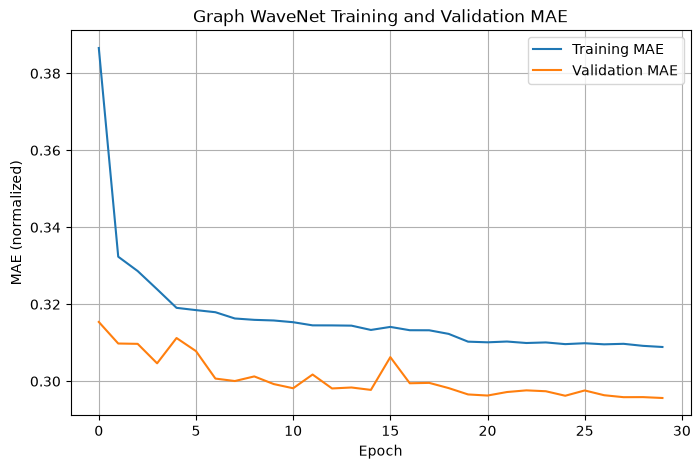

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["train"], label="Training MAE")
plt.plot(history["validation"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (normalized)")
plt.title("Graph WaveNet Training and Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Load trained model
model.load_state_dict(
    torch.load("checkpoints/gwnet_mmtd_best.pth", map_location=device, weights_only=True)
)
# eval mode
model.eval()

# Load normalization values
scaler = np.load(Path(OUTPUT_DIR) / "scaler_v3.npz")

target_mean = torch.tensor(
    scaler["mean"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, MAX_NODES)

target_std = torch.tensor(
    scaler["std"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, MAX_NODES)


In [25]:
all_predictions = []
all_targets = []
all_baseline = []

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        model_input = x.permute(0, 3, 2, 1).contiguous()
        output = model(model_input)
        prediction = output[:, :, :, HORIZON_IDX]

        # Persistence: last observed congestion in input window
        baseline = x[:, -1, :, TARGET_FEATURE].unsqueeze(1)

        all_predictions.append(prediction)
        all_targets.append(y)
        all_baseline.append(baseline)

predictions = torch.cat(all_predictions, dim=0)
targets = torch.cat(all_targets, dim=0)
baseline = torch.cat(all_baseline, dim=0)

# Normalized MAE
norm_model_mae = torch.mean(torch.abs(predictions - targets)).item()
norm_baseline_mae = torch.mean(torch.abs(baseline - targets)).item()

# Real-unit MAE
predictions_real = predictions * target_std + target_mean
targets_real = targets * target_std + target_mean
baseline_real = baseline * target_std + target_mean

model_mae = torch.mean(torch.abs(predictions_real - targets_real)).item()
baseline_mae = torch.mean(torch.abs(baseline_real - targets_real)).item()

print(f"Normalized Graph WaveNet Test MAE: {norm_model_mae:.5f}")
print(f"Normalized Persistence Test MAE:   {norm_baseline_mae:.5f}")
print("-" * 45)
print(f"Real-Unit Graph WaveNet Test MAE:  {model_mae:.5f}")
print(f"Real-Unit Persistence Test MAE:    {baseline_mae:.5f}")

Normalized Graph WaveNet Test MAE: 0.34516
Normalized Persistence Test MAE:   0.44000
---------------------------------------------
Real-Unit Graph WaveNet Test MAE:  1.90334
Real-Unit Persistence Test MAE:    2.40712


In [26]:
# save results
import json
from pathlib import Path

results = {
    "nodes": MAX_NODES,
    "input_features": features,
    "target": features[TARGET_FEATURE],
    "sequence_length": SEQ_LEN,
    "prediction_interval": "15 minutes",
    "graph_wavenet_test_mae": model_mae,
    "persistence_test_mae": baseline_mae,
    "best_validation_loss": best_val_loss
}

# Create results directory automatically
RESULTS_DIR = Path.cwd() / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save JSON file
RESULTS_PATH = RESULTS_DIR / "gwnet_mmtd_results.json"

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nResults saved to:", RESULTS_PATH)

{
    "nodes": 2780,
    "input_features": [
        "volume",
        "occ",
        "conges_levl",
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
        "road_Oneway",
        "road_RoadType",
        "road_Length",
        "road_Tunnel",
        "road_SpeedLimit",
        "road_InDegree",
        "road_OutDegree",
        "road_BetweennessCentrality",
        "road_ClosenessCentrality",
        "road_Heading",
        "road_Curviness",
        "road_CurvatureRatio",
        "road_x",
        "road_y",
        "road_poi_count",
        "road_poi_density",
        "road_work_count",
        "road_work_density",
        "road_residential_count",
        "road_residential_density",
        "road_education_count",
        "road_education_density",
        "road_medical_count",
        "road_medical_density",
        "road_food_count",
        "road_food_density",
        "road_shopping_count",
        "road_shopping_density",
        "roa

In [27]:
import pandas as pd

sample_idx = 0
node_id = 0

model.eval()
x, y = test_loader.dataset[sample_idx]
x = x.unsqueeze(0).to(device)
y = y.unsqueeze(0).to(device)

model_input = x.permute(0, 3, 2, 1).contiguous()

with torch.no_grad():
    output = model(model_input)
    prediction = output[:, :, :, HORIZON_IDX]

prediction_real = prediction * target_std + target_mean
actual_real = y * target_std + target_mean

feature_values = x[0, :, node_id, :].cpu().numpy()
feature_df = pd.DataFrame(feature_values, columns=features)
feature_df.insert(0, "Timestep", range(1, SEQ_LEN + 1))

print(f"\nInput feature values for Node {node_id} (Sample {sample_idx}):")
display(feature_df)

results_df = pd.DataFrame({
    "Node": range(MAX_NODES),
    "Predicted Congestion": prediction_real[0, 0].cpu().numpy(),
    "Actual Congestion": actual_real[0, 0].cpu().numpy(),
})
results_df["Abs Error"] = (
    results_df["Predicted Congestion"] - results_df["Actual Congestion"]
).abs()

display(results_df)


Input feature values for Node 0 (Sample 0):


,Timestep,volume,occ,conges_levl,temperature_2m_C,relative_humidity_2m_percent,precipitation_mm,road_Oneway,road_RoadType,road_Length,...,road_other_density,road_work_residential_ratio,road_commercial_residential_ratio,road_entertainment_residential_ratio,road_poi_diversity,road_poi_mix_entropy,road_weekday_dominance,road_peak_hour_impact,road_all_day_impact,road_weekend_impact
0,1,-0.214051,-0.822761,-0.219130,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
1,2,-0.622365,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
2,3,-0.156354,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
3,4,-0.560230,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
4,5,-0.156354,-0.822761,-0.488828,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
5,6,0.127690,0.170028,0.185417,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
6,7,-0.107534,0.170028,0.050568,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
7,8,-0.009894,0.170028,-0.084281,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
8,9,0.034488,0.170028,0.050568,0.960588,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
9,10,0.132128,-0.822761,-0.084281,0.960588,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335


,Node,Predicted Congestion,Actual Congestion,Abs Error
0,0,13.999434,15.0,1.000566
1,1,8.038300,10.0,1.961700
2,2,18.084488,17.0,1.084488
3,3,0.873194,0.0,0.873194
4,4,10.770977,11.0,0.229023
...,...,...,...,...
2775,2775,7.200741,8.0,0.799259
2776,2776,9.131179,11.0,1.868821
2777,2777,9.155187,11.0,1.844813
2778,2778,15.467270,17.0,1.532730


In [28]:

# 2. Check un-normalized test sample values from Cell 23
print("Un-normalized actual_real -> min:", actual_real.min().item(), "max:", actual_real.max().item())
print("Un-normalized prediction_real -> min:", prediction_real.min().item(), "max:", prediction_real.max().item())


Un-normalized actual_real -> min: 0.0 max: 75.0
Un-normalized prediction_real -> min: 0.08496682345867157 max: 69.70491790771484


In [ ]:
# TO DO - Check for road length in dataset - transform congestion into travel time with road length

In [ ]:
# import h5py
# import json

# DATA_DIR = "/data/mmtd"

# for filename in ["distance_matrix.h5", "road_info.h5"]:
#     path = f"{DATA_DIR}/{filename}"

#     print(f"\n{'='*60}")
#     print(filename)

#     with h5py.File(path, "r") as f:
#         readme = json.loads(f["README"].asstr()[()])
#         print(json.dumps(readme, indent=2))

In [ ]:
# import json
# import numpy as np
# import h5py

# with h5py.File(DIST_PATH, "r") as f:
#     if "README" in f:
#         print(f["README"].asstr()[()])

# print("dist min/p1/p5/p10/median/max:",
#       np.percentile(finite_dists, [0, 1, 5, 10, 50, 100]))
# print("Current sigma:", sigma)

{
  "file_description": "Madrid road network distance matrix in HDF5 format",
  "data_structure": {
    "data/values": "2D array with shape (n_nodes, n_nodes)",
    "metadata/nodes": "Node IDs for both rows and columns"
  },
  "matrix_description": {
    "content": "Shortest path distances between nodes",
    "unit": "kilometers",
    "node_type": "node IDs from constructed line graph based on OSM"
  },
  "usage_example": "\n            import h5py\n            import pandas as pd\n\n            # Read the distance matrix\n            with h5py.File('distance_matrix.h5', 'r') as f:\n                distance_matrix = f['data/values'][:]  # \u6539\u4e3avalues\n                nodes = f['metadata/nodes'][:]\n                # Convert to pandas DataFrame with proper index and columns\n                df = pd.DataFrame(distance_matrix, \n                                index=nodes, \n                                columns=nodes)\n        "
}
dist min/p1/p5/p10/median/max: [2.38150009e-03 1